# Assignment 3 
## BBBP molecular property prediction


Student name / ID: Indira Duisembayeva | 25011125

## Task A. 
1. Task and scientific scope
The input to the model is a molecule represented by SMILES and converted to an atom–bond graph. Output is one graph-level probability of BBB penetration. Unit of analysis: a molecule, not an atom or patient. Label 1 means the curated dataset labels it penetrating, while label 0 means non-penetrating. Intended use is educational benchmark comparison, not prescribing, safety assessment, causality or clinical deployment.

### Setup and settings


In [2]:
%matplotlib inline
"""Revised BBBP experiment. Validation-selected checkpoints; test-set reuse disclosed."""

from pathlib import Path
import copy, json, random, hashlib, platform
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool
from torch_geometric.utils.smiles import x_map, e_map
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
)
import matplotlib.pyplot as plt
import networkx as nx

ROOT = Path.cwd()
OUT = ROOT / "results"
OUT.mkdir(exist_ok=True)
SPLIT_SEED = 42
SEEDS = [11, 22, 33]
CONFIG = dict(
    hidden=64,
    layers=2,
    dropout=0.2,
    learning_rate=0.001,
    weight_decay=0.0001,
    batch_size=64,
    epochs=80,
    patience=15,
)
RDLogger.DisableLog("rdApp.*")
torch.set_num_threads(2)
from IPython.display import display
import importlib.metadata as metadata


/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Reporducibility helpers to set random seed and save the figures.

In [3]:
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


In [4]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()


### Load, inspect and clean the data
This function audits the source CSV and PyG graphs, removes conflicts and duplicates, and returns the retained molecules and graphs.

In [5]:
def inspect_clean():
    ds = MoleculeNet(root=str(ROOT / "data"), name="BBBP", force_reload=True)
    source = pd.read_csv(ds.raw_paths[0])
    source_valid = source.smiles.map(lambda s: (m := Chem.MolFromSmiles(s)) is not None and m.GetNumAtoms() > 0)
    source.assign(valid_smiles=source_valid).to_csv(OUT / "source_csv_audit.csv", index=False)
    rows = []
    for i, g in enumerate(ds):
        mol = Chem.MolFromSmiles(g.smiles)
        y = float(g.y.reshape(-1)[0])
        valid = mol is not None and mol.GetNumAtoms() > 0 and (g.num_nodes > 0)
        rows.append(
            dict( raw_id=i, smiles=g.smiles, y=y, valid=valid, canonical=(Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True) if valid else None), atoms=g.num_nodes, bonds=g.num_edges // 2,))
    raw = pd.DataFrame(rows)
    eligible = raw[raw.valid & np.isfinite(raw.y) & raw.y.isin([0, 1])].copy()
    groups = eligible.groupby("canonical")
    duplicate = eligible[eligible.canonical.duplicated(False)].copy()
    conflicts = groups.y.nunique()
    conflict_keys = conflicts[conflicts > 1].index
    conflict = eligible[eligible.canonical.isin(conflict_keys)]
    clean = (eligible[~eligible.canonical.isin(conflict_keys)].drop_duplicates("canonical").reset_index(drop=True))
    audit = dict(
        source_csv_records=len(source),
        source_invalid_or_empty=int((~source_valid).sum()),
        source_nonfinite_labels=int((~np.isfinite(source.p_np)).sum()),
        source_positive=int((source.p_np == 1).sum()),
        source_negative=int((source.p_np == 0).sum()),
        loader_records=len(ds),
        raw_records=len(raw),
        nonfinite_labels=int((~np.isfinite(raw.y)).sum()),
        invalid_or_empty=int((~raw.valid).sum()),
        nonbinary_labels=int((np.isfinite(raw.y) & ~raw.y.isin([0, 1])).sum()),
        duplicate_groups=int((groups.size() > 1).sum()),
        duplicate_records=len(duplicate),
        extra_duplicate_records=int((groups.size() - 1).sum()),
        duplicate_groups_with_different_original_smiles=int((groups.smiles.nunique() > 1).sum()),
        conflicting_groups=len(conflict_keys),
        conflicting_records=len(conflict),
        consistent_duplicate_records_removed=len(eligible) - len(conflict) - len(clean),
        retained=len(clean),
    )
    graphs = []
    for j, row in clean.iterrows():
        g = ds[int(row.raw_id)].clone()
        g.sample_id = torch.tensor([j])
        graphs.append(g)
    assert all((g.num_nodes > 0 and torch.isfinite(g.y).all() for g in graphs))
    raw.to_csv(OUT / "raw_audit.csv", index=False)
    duplicate.to_csv(OUT / "duplicates.csv", index=False)
    conflict.to_csv(OUT / "conflicts.csv", index=False)
    clean.to_csv(OUT / "clean_manifest.csv", index=False)
    (OUT / "cleaning_summary.json").write_text(json.dumps(audit, indent=2))
    print(json.dumps(audit, indent=2))
    print("Raw classes:", raw.y.value_counts(dropna=False).to_dict())
    print("Raw proportions:", raw.y.value_counts(normalize=True, dropna=False).to_dict())
    print("Clean classes:", clean.y.value_counts().to_dict(), "proportions:", clean.y.value_counts(normalize=True).to_dict(),)
    print(clean[["atoms", "bonds"]].describe().round(2).to_string())
    clean[["atoms", "bonds"]].hist(bins=35, figsize=(9, 3))
    savefig("size_distributions")
    return (ds, clean, graphs, audit)


Python: 3.13.5 Device: CPU
{'torch': '2.15.0', 'torch-geometric': '2.8.1', 'rdkit': '2024.9.6', 'scikit-learn': '1.9.1', 'numpy': '2.4.6', 'pandas': '3.1.1'}


Processing...
/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'O=N([O-])C1=C(CN=C1NCCSCc2ncccc2)Cc3ccccc3' since it resulted in zero atoms
  self.process()
/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'c1(nc(NC(N)=[NH2])sc1)CSCCNC(=[NH]C#N)NC' since it resulted in zero atoms
  self.process()
/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/torch_geometric/data/dataset.py:266: UserWarning: Skipping molecule 'Cc1nc(sc1)\[NH]=C(\N)N' since it resulted in zero atoms
  self.process()
/Users/indira.duisembayeva/Documents/miccai_workshop/Assignment3_Final_Audited/notebook/.venv/lib/python3.13/site-packages/torch_geometric/data/dataset.p

{
  "source_csv_records": 2050,
  "source_invalid_or_empty": 11,
  "source_nonfinite_labels": 0,
  "source_positive": 1567,
  "source_negative": 483,
  "loader_records": 2039,
  "raw_records": 2039,
  "nonfinite_labels": 0,
  "invalid_or_empty": 0,
  "nonbinary_labels": 0,
  "duplicate_groups": 60,
  "duplicate_records": 124,
  "extra_duplicate_records": 64,
  "duplicate_groups_with_different_original_smiles": 60,
  "conflicting_groups": 10,
  "conflicting_records": 20,
  "consistent_duplicate_records_removed": 54,
  "retained": 1965
}
Raw classes: {1.0: 1560, 0.0: 479}
Raw proportions: {1.0: 0.7650809220205983, 0.0: 0.23491907797940167}
Clean classes: {1.0: 1500, 0.0: 465} proportions: {1.0: 0.7633587786259542, 0.0: 0.2366412213740458}
         atoms    bonds
count  1965.00  1965.00
mean     24.22    26.13
std      10.67    11.79
min       2.00     1.00
25%      18.00    19.00
50%      23.00    25.00
75%      29.00    31.00
max     132.00   145.00


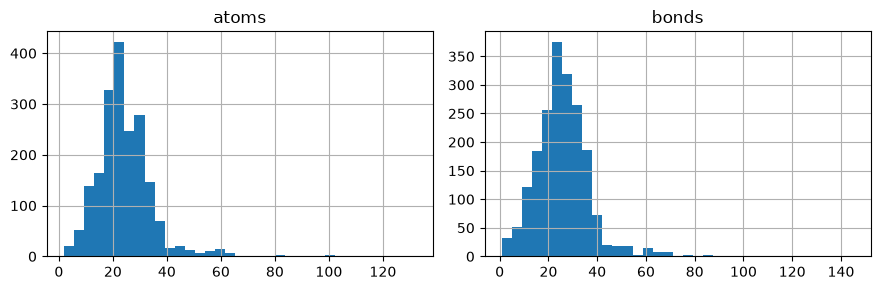

In [6]:
print("Python:", platform.python_version(), "Device: CPU")
print(
    { p: metadata.version(p)
        for p in [
            "torch",
            "torch-geometric",
            "rdkit",
            "scikit-learn",
            "numpy",
            "pandas",
        ]
    }
)
seed_all(SPLIT_SEED)
ds, clean, graphs, cleaning = inspect_clean()


### Cleaning decisions
Canonical isomeric SMILES preserve stereochemistry. We do not strip salts, neutralize, or merge tautomers: these are extra scientific decisions and could merge distinct records. Invalid/empty structures and nonfinite/nonbinary labels are excluded. All conflicting canonical-label groups are removed; consistent duplicate groups retain the first raw record. The audit files retain original row IDs and original SMILES for checking equivalent representations. Cleaning precedes both splits; raw counts and cleaned counts are distinct.

**Observed audit:** the source CSV has 2,050 records, including 11 invalid/empty structures. This PyG version skips these before returning 2,039 graphs. After removing 20 conflicting-label records and 54 redundant consistent duplicates, 1,965 remain (1,500 positive, 465 negative). `raw_id` refers to the loader index; `source_csv_audit.csv` separately preserves the downloaded CSV rows.

### Task B: Molecular graphs and batching
PyG `x` contains nine categorical columns in order: atomic number; chirality; total degree; formal charge; total hydrogen count; radical electron count; hybridization; aromaticity; ring membership. `edge_attr` contains bond type, stereochemistry, and conjugation. Every feature column has its own trainable embedding of width 64, summed within atoms/bonds. Integer codes index a vocabulary; they are never treated as continuous measurements. Full category vocabularies are printed below.

`edge_index` has shape [2, 2B] because every undirected chemical bond has two directed messages. Node and bond rows align with their feature tensors. Atom-index labels identify the same atom in both views (RDKit may omit the zero map label). Hydrogens are implicit. The network drawing changes layout, not connectivity.

A batch concatenates node/edge features and offsets edge indices, `batch` maps each node to its molecule and `y` contains one label per graph. Pooling uses this mapping, so output is one logit per graph.

In this cell we show molecules, compare chemical and graph views, then check that each graph appears exactly once in a DataLoader batch.

In [7]:
def graph_views(clean, graphs):
    ids = []
    for y in [0, 1]:
        ids += (
            clean[clean.y == y].sort_values(["atoms", "raw_id"]).head(3).index.tolist()
        )
    mols = [Chem.MolFromSmiles(clean.loc[i, "smiles"]) for i in ids]
    img = Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=(350, 220),
        legends=[f"id {i}; label {int(clean.loc[i, 'y'])}" for i in ids],
        useSVG=False,
    )
    (
        (OUT / "six_molecules.png").write_bytes(img.data)
        if hasattr(img, "data")
        else img.save(str(OUT / "six_molecules.png"))
    )
    from IPython.display import display

    display(img)
    display(clean.loc[ids, ["smiles", "y"]])
    i = ids[0]
    g = graphs[i]
    mol = Chem.MolFromSmiles(g.smiles)
    for a in mol.GetAtoms():
        a.SetAtomMapNum(a.GetIdx())
    fig, axs = plt.subplots(1, 2, figsize=(10, 3))
    axs[0].imshow(Draw.MolToImage(mol, size=(600, 350)))
    axs[0].axis("off")
    graph = nx.Graph()
    graph.add_nodes_from(range(g.num_nodes))
    graph.add_edges_from(g.edge_index.T.tolist())
    nx.draw_networkx(
        graph,
        pos=nx.spring_layout(graph, seed=42),
        labels={a.GetIdx(): f"{a.GetIdx()}:{a.GetSymbol()}" for a in mol.GetAtoms()},
        ax=axs[1],
        node_size=600,
        font_size=8,
    )
    axs[0].set_title("Chemical structure (atom indices)")
    axs[1].set_title("Same atoms and undirected bonds")
    savefig("graph_views")
    print(
        {k: tuple(getattr(g, k).shape) for k in ["x", "edge_index", "edge_attr"]},
        "y=",
        g.y,
        "smiles=",
        g.smiles,
    )
    print("Atom columns:", list(x_map))
    print("Bond columns:", list(e_map))
    loader = DataLoader(graphs, batch_size=64, shuffle=False)
    b = next(iter(loader))
    print(
        "Batch:",
        {
            k: tuple(getattr(b, k).shape)
            for k in ["x", "edge_index", "edge_attr", "batch", "y"]
        },
    )
    seen = []
    for b in loader:
        assert b.y.numel() == b.num_graphs and torch.isfinite(b.y).all()
        assert torch.all(b.ptr[1:] - b.ptr[:-1] > 0)
        seen.extend(b.sample_id.tolist())
    assert sorted(seen) == list(range(len(graphs))) and len(set(seen)) == len(graphs)
    print(
        "PASS: finite labels, nonempty graphs, labels per graph, exact-once batching."
    )


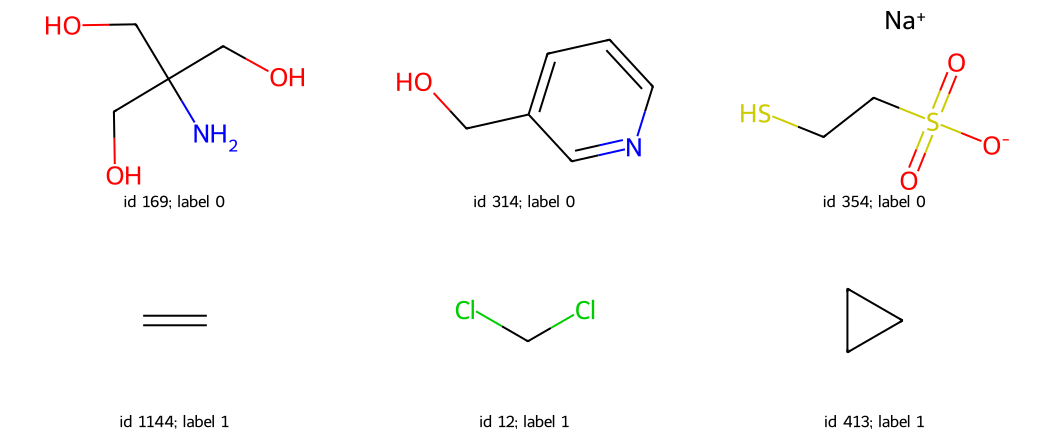

,smiles,y
169,NC(CO)(CO)CO,0.0
314,OCc1cccnc1,0.0
354,[Na+].[O-][S](=O)(=O)CCS,0.0
1144,C=C,1.0
12,C(Cl)Cl,1.0
413,C1CC1,1.0


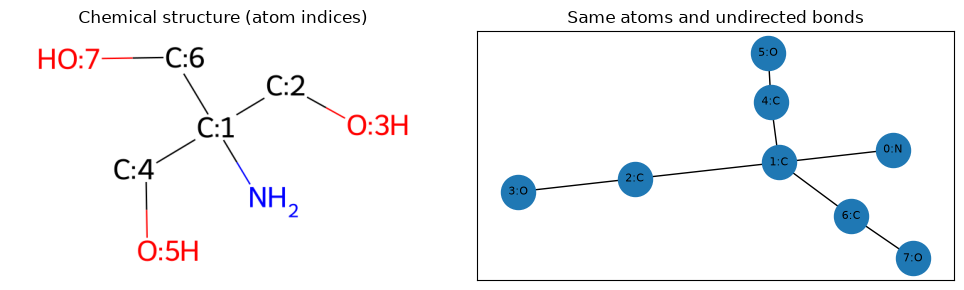

{'x': (8, 9), 'edge_index': (2, 14), 'edge_attr': (14, 3)} y= tensor([[0.]]) smiles= NC(CO)(CO)CO
Atom columns: ['atomic_num', 'chirality', 'degree', 'formal_charge', 'num_hs', 'num_radical_electrons', 'hybridization', 'is_aromatic', 'is_in_ring']
Bond columns: ['bond_type', 'stereo', 'is_conjugated']
Batch: {'x': (1522, 9), 'edge_index': (2, 3276), 'edge_attr': (3276, 3), 'batch': (1522,), 'y': (64, 1)}
PASS: finite labels, nonempty graphs, labels per graph, exact-once batching.
Complete atom vocabulary: {'atomic_num': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116

In [8]:
graph_views(clean, graphs)
print("Complete atom vocabulary:", x_map)
print("Complete bond vocabulary:", e_map)


### Task C: Two fixed split strategies
Seed 42 produces stratified random 70:15:15 partitions. Scaffold grouping uses nonchiral Bemis–Murcko scaffolds. Seeded tie order plus largest-group-first allocation to the greatest remaining target deficit approximates 70:15:15 while preserving whole groups; exact ratios may be impossible. Acyclic molecules all share the empty scaffold and stay together. Invalid molecules were already removed. The algorithm does not optimize labels or performance; class imbalance may differ across subsets.

Coverage, canonical uniqueness, and scaffold disjointness are asserted. The requested subset label summaries are descriptive audits; no revised test predictions are computed until the revised checkpoints and thresholds are frozen; the original test results had already been viewed. Random splits can put structurally similar analogues in train and test even after exact deduplication, making estimates optimistic for unseen chemistry. Scaffold splitting reduces this overlap but does not ensure complete chemical dissimilarity.

Here we construct the partitions and assert complete coverage and no forbidden overlap.

In [9]:
def make_splits(clean):
    ids = np.arange(len(clean))
    y = clean.y.to_numpy().astype(int)
    tr, other = train_test_split(
        ids, test_size=0.3, stratify=y, random_state=SPLIT_SEED
    )
    va, te = train_test_split(
        other, test_size=0.5, stratify=y[other], random_state=SPLIT_SEED
    )
    splits = {"random": dict(train=tr, val=va, test=te)}
    scaffolds = [
        MurckoScaffold.MurckoScaffoldSmiles(smiles=s, includeChirality=False)
        for s in clean.canonical
    ]
    groups = {}
    for i, s in enumerate(scaffolds):
        groups.setdefault(s, []).append(i)
    rng = np.random.default_rng(SPLIT_SEED)
    ordered = list(groups.values())
    rng.shuffle(ordered)
    ordered.sort(key=len, reverse=True)
    target = np.array([0.7, 0.15, 0.15]) * len(clean)
    bins = [[], [], []]
    for group in ordered:
        deficit = target - np.array([len(b) for b in bins])
        k = int(np.argmax(deficit))
        bins[k].extend(group)
    splits["scaffold"] = {
        k: np.array(v, dtype=int) for k, v in zip(["train", "val", "test"], bins)
    }
    report = []
    for strategy, parts in splits.items():
        assert sorted(np.concatenate(list(parts.values())).tolist()) == ids.tolist()
        for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
            assert not set(parts[a]) & set(parts[b])
            assert not set(clean.iloc[parts[a]].canonical) & set(
                clean.iloc[parts[b]].canonical
            )
            if strategy == "scaffold":
                assert not {scaffolds[i] for i in parts[a]} & {
                    scaffolds[i] for i in parts[b]
                }
        for subset, idx in parts.items():
            assert len(np.unique(y[idx])) == 2, "Both classes required for ROC-AUC."
            report.append(
                dict(
                    split=strategy,
                    subset=subset,
                    n=len(idx),
                    fraction=len(idx) / len(clean),
                    positive=int(y[idx].sum()),
                    positive_fraction=y[idx].mean(),
                    unique_scaffolds=len({scaffolds[i] for i in idx}),
                )
            )
    report = pd.DataFrame(report)
    report.to_csv(OUT / "split_summary.csv", index=False)
    (OUT / "splits.json").write_text(
        json.dumps(
            {s: {k: v.tolist() for k, v in p.items()} for s, p in splits.items()},
            indent=2,
        )
    )
    print(report.to_string(index=False))
    print(
        "Acyclic molecules:",
        scaffolds.count(""),
        "PASS: coverage, disjoint indices/canonical SMILES/scaffolds.",
    )
    return (splits, report)


Building Morgan fingerprints: The same fingerprint definition is used for logistic regression and the later similarity analysis.

In [10]:
def fingerprints(clean):
    gen = rdFingerprintGenerator.GetMorganGenerator(
        radius=2, fpSize=2048, includeChirality=True
    )
    bits = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in clean.canonical]
    X = np.asarray([np.asarray(b) for b in bits], dtype=np.float32)
    return (X, bits)


In [11]:
splits, split_summary = make_splits(clean)
X, bits = fingerprints(clean)


   split subset    n  fraction  positive  positive_fraction  unique_scaffolds
  random  train 1375  0.699746      1050           0.763636               773
  random    val  295  0.150127       225           0.762712               225
  random   test  295  0.150127       225           0.762712               226
scaffold  train 1375  0.699746      1045           0.760000               466
scaffold    val  295  0.150127       226           0.766102               277
scaffold   test  295  0.150127       229           0.776271               277
Acyclic molecules: 95 PASS: coverage, disjoint indices/canonical SMILES/scaffolds.


### Task D: Fingerprint baseline
Morgan radius 2, 2048 bits, chirality enabled. A bit records presence of a hashed local atom environment extending up to two bonds, where collisions can occur. Logistic regression uses L2 regularization and balanced weights computed by sklearn from training labels only. Validate C in [0.01, 0.1, 1, 10] with ROC-AUC, ties favor the smaller C, solver liblinear, max_iter=2000, seed 42. The decision threshold is selected by maximizing validation F1 over thresholds from 0.05 to 0.95 in increments of 0.01. Ties favour the threshold closest to 0.5, then the smaller threshold.

### Task E. Bond-aware GNN and selection protocol
Two GINEConv layers, each with Linear(64,64)–ReLU–Linear(64,64), trainable epsilon, then BatchNorm1d, ReLU and dropout 0.2. Bond embeddings enter neighbor messages through ReLU(node + bond). Mean graph pooling followed by Linear(64,64)–ReLU–dropout–Linear(64,1) returns a logit. Mean pooling limits direct graph-size scaling but may discard size information.

Weighted BCEWithLogitsLoss combines stable binary logistic loss and training-only positive weight n_negative/n_positive. Since positives are common, this weight may be less than 1. Adam lr=0.001, weight_decay=0.0001; batch 64; at most 80 epochs; patience 15; checkpoint when validation ROC-AUC improves by >0.0001. Restore that checkpoint, then choose validation F1 threshold by the same rule as LR. For this revision the architecture is fixed before retraining, but it was chosen after exploratory validation comparisons conducted after the original test results were seen. New test outcomes do not select checkpoints or thresholds. Seeds **11, 22, 33** vary initialization/dropout/shuffling, while the split remains fixed. CPU deterministic operations and two threads are used.

All eight models are fit and selection settings are written to `frozen_selection.json` before any test inference.

Why we chose BatchNorm and mean? Earlier mean validation AUC was 0.915/0.893 (random/scaffold) for BatchNorm + mean versus 0.911/0.881 for LayerNorm + max. These are adaptive validation comparisons, not independent performance estimates. BatchNorm normalizes over all nodes in the training minibatch and uses running statistics for validation/test; larger graphs contribute more nodes. Adam remains lr=0.001, weight_decay=0.0001, betas=(0.9,0.999), eps=1e-8.

Selectign a threshold using validation data:

In [12]:
def threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    scores = [f1_score(y, p >= t, zero_division=0) for t in grid]
    return float(
        sorted(zip(grid, scores), key=lambda v: (-v[1], abs(v[0] - 0.5), v[0]))[0][0]
    )


Defining the GNN architecture, where it encodes atoms and bonds → two message-passing layers → mean pooling → one molecular logit.

In [13]:
class GNN(nn.Module):

    def __init__(self):
        super().__init__()
        h = CONFIG["hidden"]
        self.atoms = nn.ModuleList([nn.Embedding(len(v), h) for v in x_map.values()])
        self.bonds = nn.ModuleList([nn.Embedding(len(v), h) for v in e_map.values()])
        self.convs = nn.ModuleList(
            [
                GINEConv(
                    nn.Sequential(nn.Linear(h, h), nn.ReLU(), nn.Linear(h, h)),
                    train_eps=True,
                )
                for _ in range(CONFIG["layers"])
            ]
        )
        self.norms = nn.ModuleList([nn.BatchNorm1d(h) for _ in self.convs])
        self.drop = nn.Dropout(CONFIG["dropout"])
        self.head = nn.Sequential(
            nn.Linear(h, h), nn.ReLU(), nn.Dropout(CONFIG["dropout"]), nn.Linear(h, 1)
        )

    def forward(self, b):
        x = sum((e(b.x[:, j]) for j, e in enumerate(self.atoms)))
        edge = sum((e(b.edge_attr[:, j]) for j, e in enumerate(self.bonds)))
        for conv, norm in zip(self.convs, self.norms):
            x = self.drop(torch.relu(norm(conv(x, b.edge_index, edge))))
        return self.head(global_mean_pool(x, b.batch)).reshape(-1)


Here we run inference without updating weights This helper puts the model in evaluation mode and returns probabilities and, optionally, loss.

In [14]:
def predict(model, graphs, idx, criterion=None):
    model.eval()
    ps = []
    ys = []
    loss = 0
    with torch.no_grad():
        for b in DataLoader([graphs[i] for i in idx], batch_size=64, shuffle=False):
            logits = model(b)
            y = b.y.reshape(-1).float()
            ps.extend(logits.sigmoid().tolist())
            ys.extend(y.tolist())
            if criterion is not None:
                loss += criterion(logits, y).item() * len(y)
    return (np.array(ps), np.array(ys), loss / len(idx))


Training and freezing all model choices
For each fixed split: tune logistic regression using validation data, then train the GNN with three seeds. Restore validation checkpoints and save thresholds before test evaluation.

In [15]:
def fit_all(clean, graphs, splits, X):
    y = clean.y.to_numpy().astype(int)
    runs = []
    search = []
    validation_records = []

    def record_validation(model_name, strategy, seed, indices, labels, probabilities):
        for i, label, probability in zip(indices, labels, probabilities):
            validation_records.append(dict(model=model_name, split=strategy, seed=seed,
                                           sample_id=int(i), y=int(label), probability=float(probability)))
    print(
        "GNN parameters:",
        sum((p.numel() for p in GNN().parameters())),
        "configuration:",
        CONFIG,
    )
    for strategy, parts in splits.items():
        tr, va = (parts["train"], parts["val"])
        best = None
        for C in [0.01, 0.1, 1.0, 10.0]:
            m = LogisticRegression(
                C=C,
                class_weight="balanced",
                solver="liblinear",
                max_iter=2000,
                random_state=SPLIT_SEED,
            ).fit(X[tr], y[tr])
            p = m.predict_proba(X[va])[:, 1]
            score = roc_auc_score(y[va], p)
            search.append(dict(split=strategy, C=C, val_roc_auc=score))
            if best is None or score > best[0]:
                best = (score, m, C, p)
        score, m, C, p = best
        record_validation("Morgan LR", strategy, SPLIT_SEED, va, y[va], p)
        runs.append(
            dict(
                split=strategy,
                model="Morgan LR",
                seed=SPLIT_SEED,
                estimator=m,
                threshold=threshold(y[va], p),
                C=C,
                val_auc=score,
            )
        )
        for seed in SEEDS:
            seed_all(seed)
            model = GNN()
            pos_weight = torch.tensor(
                [(len(tr) - y[tr].sum()) / y[tr].sum()], dtype=torch.float32
            )
            criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
            opt = torch.optim.Adam(
                model.parameters(),
                lr=CONFIG["learning_rate"],
                weight_decay=CONFIG["weight_decay"],
            )
            loader = DataLoader(
                [graphs[i] for i in tr],
                batch_size=CONFIG["batch_size"],
                shuffle=True,
                generator=torch.Generator().manual_seed(seed),
            )
            hist = []
            bestscore = -np.inf
            beststate = None
            bestepoch = 0
            for epoch in range(1, CONFIG["epochs"] + 1):
                model.train()
                total = 0
                for b in loader:
                    opt.zero_grad()
                    logits = model(b)
                    loss = criterion(logits, b.y.reshape(-1).float())
                    loss.backward()
                    opt.step()
                    total += loss.item() * b.num_graphs
                vp, vy, vl = predict(model, graphs, va, criterion)
                score = roc_auc_score(vy, vp)
                hist.append(
                    dict(
                        epoch=epoch,
                        train_loss=total / len(tr),
                        val_loss=vl,
                        val_roc_auc=score,
                    )
                )
                if score > bestscore + 0.0001:
                    bestscore = score
                    beststate = copy.deepcopy(model.state_dict())
                    bestepoch = epoch
                if epoch - bestepoch >= CONFIG["patience"]:
                    break
            model.load_state_dict(beststate)
            vp, vy, _ = predict(model, graphs, va)
            record_validation("GINE", strategy, seed, va, vy, vp)
            h = pd.DataFrame(hist)
            h.to_csv(OUT / f"history_{strategy}_{seed}.csv", index=False)
            runs.append(
                dict(
                    split=strategy,
                    model="GINE",
                    normalization="BatchNorm",
                    pooling="mean",
                    seed=seed,
                    estimator=model,
                    threshold=threshold(vy, vp),
                    val_auc=bestscore,
                    best_epoch=bestepoch,
                    history=h,
                    pos_weight=float(pos_weight.item()),
                )
            )
            print(
                f"{strategy} seed {seed}: epochs={len(h)}, best epoch={bestepoch}, validation AUC={bestscore:.3f}",
                flush=True,
            )
    pd.DataFrame(search).to_csv(OUT / "baseline_search.csv", index=False)
    frozen = [
        {k: v for k, v in r.items() if k not in ["estimator", "history"]} for r in runs
    ]
    (OUT / "frozen_selection.json").write_text(json.dumps(frozen, indent=2))
    pd.DataFrame(validation_records).to_csv(OUT / "validation_predictions.csv", index=False)
    return runs


In [16]:
runs = fit_all(clean, graphs, splits, X)


GNN parameters: 34371 configuration: {'hidden': 64, 'layers': 2, 'dropout': 0.2, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'batch_size': 64, 'epochs': 80, 'patience': 15}
random seed 11: epochs=56, best epoch=41, validation AUC=0.915
random seed 22: epochs=36, best epoch=21, validation AUC=0.908
random seed 33: epochs=40, best epoch=25, validation AUC=0.921
scaffold seed 11: epochs=55, best epoch=40, validation AUC=0.891
scaffold seed 22: epochs=52, best epoch=37, validation AUC=0.894
scaffold seed 33: epochs=74, best epoch=59, validation AUC=0.895


Inspecting training/validation loss and validation ROC-AUC before inspecting the revised test results.

In [17]:
def learning_curves(runs):
    fig, axs = plt.subplots(2, 3, figsize=(12, 6))
    for row, strategy in enumerate(["random", "scaffold"]):
        for col, seed in enumerate(SEEDS):
            r = next(
                (
                    r
                    for r in runs
                    if r["model"] == "GINE"
                    and r["split"] == strategy
                    and (r["seed"] == seed)
                )
            )
            h = r["history"]
            ax = axs[row, col]
            ax.plot(h.epoch, h.train_loss, label="train BCE")
            ax.plot(h.epoch, h.val_loss, label="validation BCE")
            ax.axvline(r["best_epoch"], color="gray", ls=":")
            ax2 = ax.twinx()
            ax2.plot(
                h.epoch,
                h.val_roc_auc,
                color="green",
                ls="--",
                label="validation ROC-AUC",
            )
            ax2.set_ylim(0, 1)
            ax.set_title(f"{strategy}, seed {seed}")
            ax.set_xlabel("epoch")
            ax.set_ylabel("weighted BCE")
            if row == 0 and col == 0:
                ax.legend(fontsize=7, loc="upper left")
                ax2.legend(fontsize=7, loc="lower right")
            peak = h.loc[h.val_roc_auc.idxmax()]
            print(
                f"{strategy}/{seed}: train BCE {h.train_loss.iloc[0]:.3f}->{h.train_loss.iloc[-1]:.3f}; val BCE {h.val_loss.iloc[0]:.3f}->{h.val_loss.iloc[-1]:.3f}; peak validation AUC {peak.val_roc_auc:.3f} at epoch {int(peak.epoch)}. Late AUC {h.val_roc_auc.iloc[-1]:.3f}."
            )
    savefig("learning_curves")


random/11: train BCE 0.310->0.111; val BCE 0.289->0.376; peak validation AUC 0.915 at epoch 41. Late AUC 0.902.
random/22: train BCE 0.309->0.121; val BCE 0.288->0.301; peak validation AUC 0.908 at epoch 21. Late AUC 0.893.
random/33: train BCE 0.299->0.118; val BCE 0.284->0.250; peak validation AUC 0.921 at epoch 25. Late AUC 0.906.
scaffold/11: train BCE 0.318->0.114; val BCE 0.299->0.288; peak validation AUC 0.891 at epoch 40. Late AUC 0.866.
scaffold/22: train BCE 0.316->0.106; val BCE 0.289->0.232; peak validation AUC 0.894 at epoch 37. Late AUC 0.883.
scaffold/33: train BCE 0.307->0.097; val BCE 0.286->0.254; peak validation AUC 0.895 at epoch 59. Late AUC 0.867.


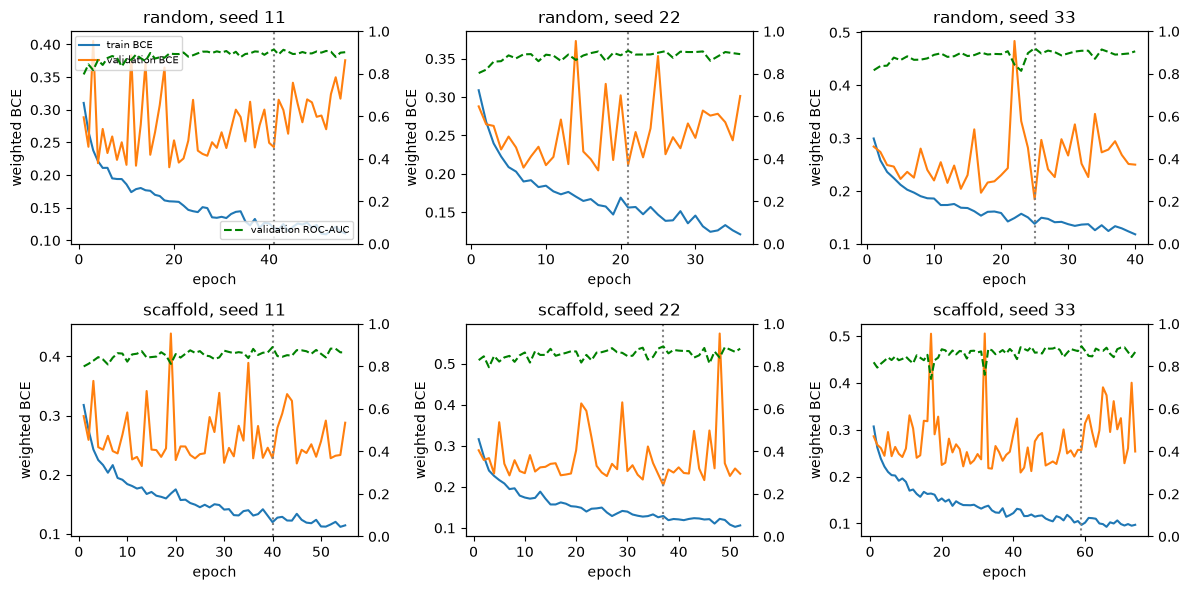

In [18]:
learning_curves(runs)


### Interpreting training before inspecting the revised test results
Decreasing train loss with worsening validation loss indicates overfitting, oscillating validation curves suggest instability on the small validation sample. Persistently poor train and validation performance suggests underfitting. Training loss includes dropout and minibatch BatchNorm statistics, whereas validation uses dropout disabled and running BatchNorm statistics, so their gap is not a pure generalization-gap estimate. Early stopping can limit deterioration but does not eliminate selection variance. The report summarizes the observed curves. Training loss decreases across all runs, while validation loss fluctuates and validation ROC-AUC peaks before training ends. This indicates learning with instability and overfitting risk. For example, random-split seed 11 reaches its selected validation AUC at epoch 41, while validation BCE increases from 0.289 to 0.376 over training. The selected checkpoint is restored instead of using the last epoch.

### Task F. Revised final test evaluation
The next cell below evaluates each model on its own test set once. ROC-AUC measures ranking, PR-AUC here is trapezoidal area under the precision–recall curve, average precision is also exported explicitly as a different estimator. Accuracy, sensitivity, specificity and F1 use the frozen validation threshold. Confusion matrix rows are true classes and columns predicted classes, ordered [0,1]. Dotted PR reference is test prevalence. Three-seed SD uses ddof=1 and reflects training randomness conditional on one split, not split uncertainty or a confidence interval. The random and scaffold test sets contain different molecules, comparison is descriptive, not a paired causal experiment.

Evaluating the frozen models, where we compute all required metrics, comparison tables, ROC/PR curves and confusion matrices using the frozen validation thresholds.

In [19]:
def evaluate_all(runs, clean, graphs, splits, X):
    rows = []
    predictions = []
    fig, axs = plt.subplots(2, 2, figsize=(10, 8))
    figcm, cm_axes = plt.subplots(2, 4, figsize=(12, 5.5))
    for r in runs:
        idx = splits[r["split"]]["test"]
        y = clean.iloc[idx].y.to_numpy().astype(int)
        p = (
            r["estimator"].predict_proba(X[idx])[:, 1]
            if r["model"] == "Morgan LR"
            else predict(r["estimator"], graphs, idx)[0]
        )
        r["test_p"] = p
        pred = p >= r["threshold"]
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        precision, recall, _ = precision_recall_curve(y, p)
        fpr, tpr, _ = roc_curve(y, p)
        metrics = dict(
            roc_auc=roc_auc_score(y, p),
            pr_auc=auc(recall, precision),
            average_precision=average_precision_score(y, p),
            accuracy=accuracy_score(y, pred),
            sensitivity=recall_score(y, pred),
            specificity=tn / (tn + fp),
            f1=f1_score(y, pred, zero_division=0),
        )
        rows.append(
            dict(
                model=r["model"],
                split=r["split"],
                seed=r["seed"],
                threshold=r["threshold"],
                **metrics,
            )
        )
        for i, yi, pi in zip(idx, y, p):
            predictions.append(
                dict(
                    model=r["model"],
                    split=r["split"],
                    seed=r["seed"],
                    sample_id=int(i),
                    y=int(yi),
                    probability=float(pi),
                    threshold=r["threshold"],
                )
            )
        row = 0 if r["split"] == "random" else 1
        label = f"{r['model']} s{r['seed']}"
        axs[row, 0].plot(fpr, tpr, label=f"{label} ({metrics['roc_auc']:.3f})")
        axs[row, 1].plot(recall, precision, label=f"{label} ({metrics['pr_auc']:.3f})")
        col = 0 if r["model"] == "Morgan LR" else SEEDS.index(r["seed"]) + 1
        ax = cm_axes[row, col]
        mat = np.array([[tn, fp], [fn, tp]])
        ax.imshow(mat, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(b, a, str(mat[a, b]), ha="center", va="center", color="red")
        ax.set(
            xticks=[0, 1],
            yticks=[0, 1],
            xlabel="predicted",
            ylabel="true",
            title=f"{r['split']}: {label}",
        )
    for row, strategy in enumerate(["random", "scaffold"]):
        axs[row, 0].plot([0, 1], [0, 1], "k:", alpha=0.5)
        axs[row, 0].set(
            xlabel="false positive rate", ylabel="sensitivity", title=strategy + " ROC"
        )
        prevalence = clean.iloc[splits[strategy]["test"]].y.mean()
        axs[row, 1].axhline(prevalence, color="gray", ls=":")
        axs[row, 1].set(
            xlabel="recall", ylabel="precision", title=strategy + " precision-recall"
        )
        for ax in axs[row]:
            ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(OUT / "test_curves.png", dpi=170, bbox_inches="tight")
    figcm.tight_layout()
    figcm.savefig(OUT / "confusion_matrices.png", dpi=170, bbox_inches="tight")
    plt.show()
    result = pd.DataFrame(rows)
    result.to_csv(OUT / "test_metrics.csv", index=False)
    pd.DataFrame(predictions).to_csv(OUT / "test_predictions.csv", index=False)
    cols = [
        "threshold",
        "roc_auc",
        "pr_auc",
        "accuracy",
        "sensitivity",
        "specificity",
        "f1",
    ]
    summary = []
    for (model, split), frame in result.groupby(["model", "split"], sort=False):
        summary.append(
            dict(
                model=model,
                split=split,
                **{
                    c: (
                        f"{frame[c].mean():.3f} ± {frame[c].std(ddof=1):.3f}"
                        if len(frame) > 1
                        else f"{frame[c].iloc[0]:.3f}"
                    )
                    for c in cols
                },
            )
        )
    pd.DataFrame(summary).to_csv(OUT / "comparison.csv", index=False)
    print(result.round(4).to_string(index=False))
    print("\nMean ± sample SD (three GNN seeds):")
    print(pd.DataFrame(summary).to_string(index=False))
    return result


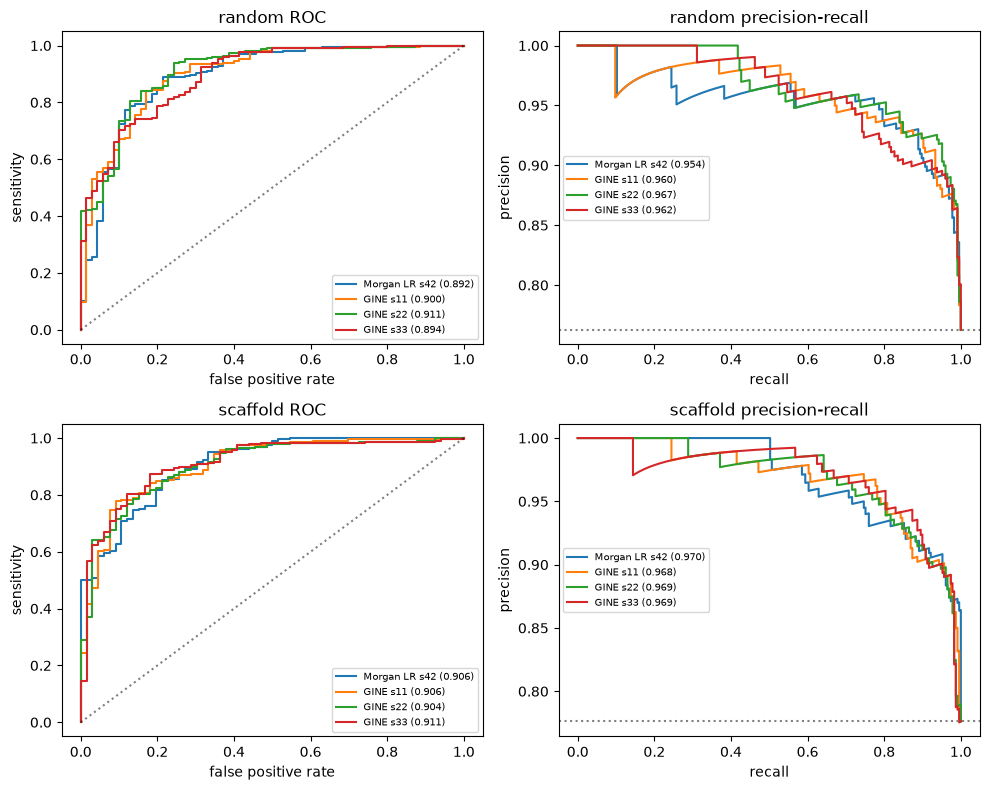

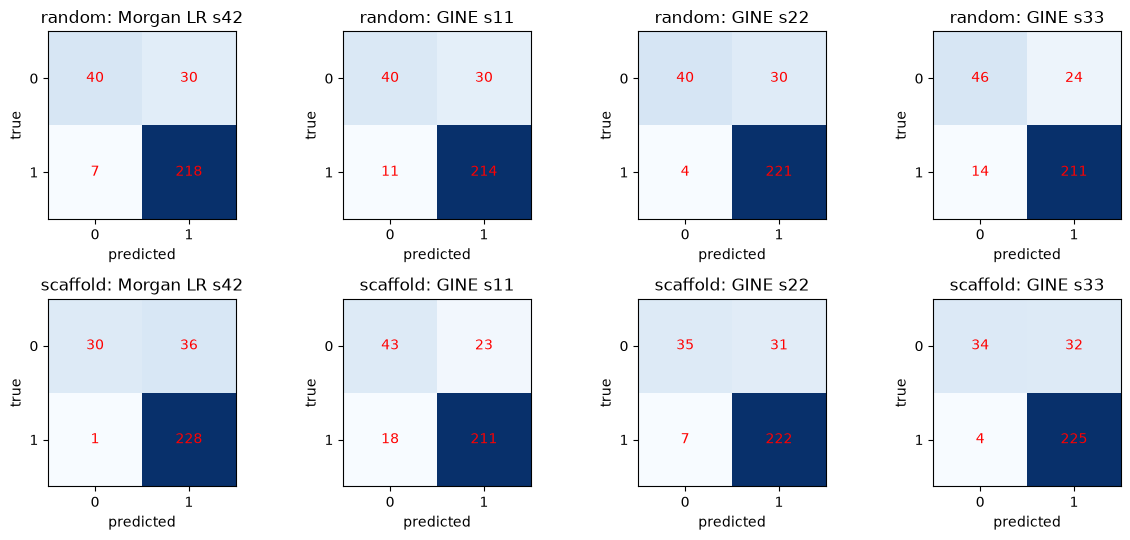

    model    split  seed  threshold  roc_auc  pr_auc  average_precision  accuracy  sensitivity  specificity     f1
Morgan LR   random    42       0.25   0.8923  0.9537             0.9539    0.8746       0.9689       0.5714 0.9218
     GINE   random    11       0.18   0.9003  0.9597             0.9599    0.8610       0.9511       0.5714 0.9126
     GINE   random    22       0.13   0.9105  0.9669             0.9670    0.8847       0.9822       0.5714 0.9286
     GINE   random    33       0.25   0.8945  0.9621             0.9622    0.8712       0.9378       0.6571 0.9174
Morgan LR scaffold    42       0.16   0.9060  0.9695             0.9696    0.8746       0.9956       0.4545 0.9249
     GINE scaffold    11       0.50   0.9058  0.9681             0.9681    0.8610       0.9214       0.6515 0.9114
     GINE scaffold    22       0.15   0.9041  0.9686             0.9686    0.8712       0.9694       0.5303 0.9212
     GINE scaffold    33       0.12   0.9111  0.9693             0.9695    0.878

In [20]:
metrics = evaluate_all(runs, clean, graphs, splits, X)


In [21]:
means = metrics.groupby(["model", "split"]).roc_auc.mean()
for strategy in ["random", "scaffold"]:
    delta = means["GINE", strategy] - means["Morgan LR", strategy]
    print(f"{strategy}: GNN mean ROC-AUC minus LR ROC-AUC = {delta:+.3f}")
for model in ["Morgan LR", "GINE"]:
    print(
        f'{model}: random minus scaffold ROC-AUC = {means[model,"random"]-means[model,"scaffold"]:+.3f}'
    )
print(
    "These are benchmark-specific comparisons; neither architecture nor splitting direction is guaranteed to win."
)


random: GNN mean ROC-AUC minus LR ROC-AUC = +0.009
scaffold: GNN mean ROC-AUC minus LR ROC-AUC = +0.001
Morgan LR: random minus scaffold ROC-AUC = -0.014
GINE: random minus scaffold ROC-AUC = -0.005
These are benchmark-specific comparisons; neither architecture nor splitting direction is guaranteed to win.


### Task G: Errors, nearest training analogues and limitations
Representative GNN seed 11 is retained from the original protocol before the revised test evaluation. Choosing the first two false positives and false negatives by stored test order, not by their confidence or visual appeal. Searching only scaffold training molecules with the same Morgan definition. Training probabilities are in-sample and may be optimistic. High similarity with opposite labels can indicate missing determinants or label uncertainty, while low similarity can indicate extrapolation.

In the following cell we inspect errors and nearest training molecules

In [22]:
def error_analysis(runs, clean, graphs, splits, X, bits):
    r = next(
        (
            r
            for r in runs
            if r["split"] == "scaffold" and r["model"] == "GINE" and (r["seed"] == 11)
        )
    )
    te = splits["scaffold"]["test"]
    tr = splits["scaffold"]["train"]
    p = r["test_p"]
    y = clean.iloc[te].y.to_numpy().astype(int)
    train_p = predict(r["estimator"], graphs, tr)[0]
    pd.DataFrame({"sample_id": tr, "probability": train_p}).to_csv(
        OUT / "error_reference_training_predictions.csv", index=False)
    selected = []
    for name, mask in [
        ("FP", (y == 0) & (p >= r["threshold"])),
        ("FN", (y == 1) & (p < r["threshold"])),
    ]:
        candidates = np.flatnonzero(mask)
        print(name, "available:", len(candidates))
        for k in candidates[:2]:
            selected.append((name, k))
    rows = []
    mols = []
    legends = []
    for name, k in selected:
        i = te[k]
        sim = np.array(
            DataStructs.BulkTanimotoSimilarity(bits[i], [bits[j] for j in tr])
        )
        n = int(sim.argmax())
        j = tr[n]
        rows.append(
            dict(
                error=name,
                test_id=int(i),
                test_smiles=clean.loc[i, "canonical"],
                test_y=int(y[k]),
                test_p=float(p[k]),
                train_id=int(j),
                train_smiles=clean.loc[j, "canonical"],
                train_y=int(clean.loc[j, "y"]),
                train_p=float(train_p[n]),
                tanimoto=float(sim[n]),
            )
        )
        mols += [
            Chem.MolFromSmiles(clean.loc[i, "canonical"]),
            Chem.MolFromSmiles(clean.loc[j, "canonical"]),
        ]
        legends += [
            f"{name} test {i}: y={y[k]}, p={p[k]:.3f}",
            f"train {j}: y={int(clean.loc[j, 'y'])}, p={train_p[n]:.3f}; T={sim[n]:.3f}",
        ]
    frame = pd.DataFrame(rows)
    frame.to_csv(OUT / "error_pairs.csv", index=False)
    if mols:
        img = Draw.MolsToGridImage(
            mols, molsPerRow=2, subImgSize=(500, 260), legends=legends
        )
        (
            (OUT / "error_pairs.png").write_bytes(img.data)
            if hasattr(img, "data")
            else img.save(str(OUT / "error_pairs.png"))
        )
        from IPython.display import display

        display(img)
        display(frame)
    if len(selected) < 4:
        print(
            "Fewer than two errors of a requested type exist; do not alter thresholds or fabricate errors."
        )
    return frame


FP available: 23
FN available: 18


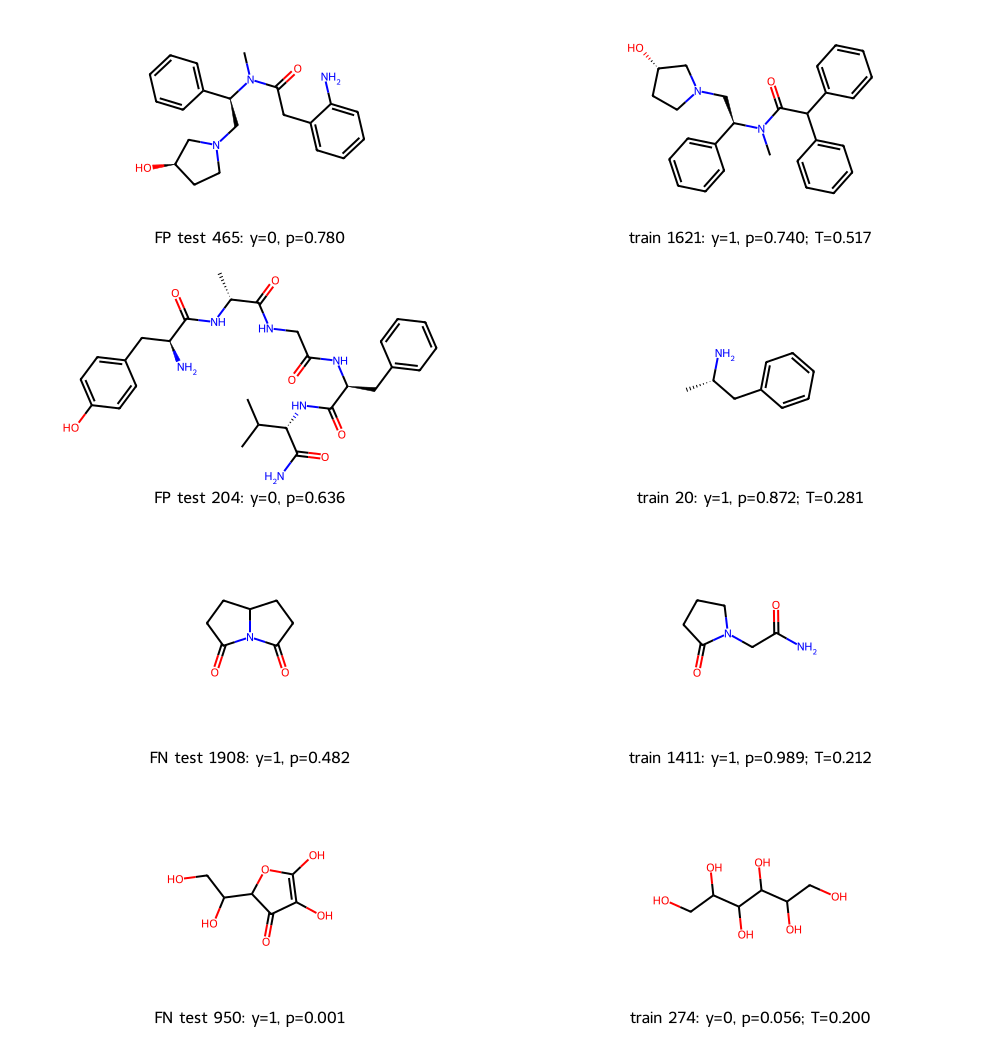

,error,test_id,test_smiles,test_y,test_p,train_id,train_smiles,train_y,train_p,tanimoto
0,FP,465,CN(C(=O)Cc1ccccc1N)[C@@H](CN1CC[C@@H](O)C1)c1c...,0,0.780038,1621,CN(C(=O)C(c1ccccc1)c1ccccc1)[C@H](CN1CC[C@H](O...,1,0.740359,0.516667
1,FP,204,CC(C)[C@H](NC(=O)[C@H](Cc1ccccc1)NC(=O)CNC(=O)...,0,0.635839,20,C[C@H](N)Cc1ccccc1,1,0.872221,0.280702
2,FN,1908,O=C1CCC2CCC(=O)N12,1,0.481967,1411,NC(=O)CN1CCCC1=O,1,0.989043,0.212121
3,FN,950,O=C1C(O)=C(O)OC1C(O)CO,1,0.001200,274,OCC(O)C(O)C(O)C(O)CO,0,0.056496,0.200000


In [24]:
errors = error_analysis(runs, clean, graphs, splits, X, bits)


In [25]:
for _, e in errors.iterrows():
    relation = "same label" if e.test_y == e.train_y else "opposite labels"
    print(
        f"{e.error} test {e.test_id}: nearest train {e.train_id}, T={e.tanimoto:.3f}, {relation}; test p={e.test_p:.3f}, train p={e.train_p:.3f}. Similarity alone does not establish why the prediction failed."
    )


FP test 465: nearest train 1621, T=0.517, opposite labels; test p=0.780, train p=0.740. Similarity alone does not establish why the prediction failed.
FP test 204: nearest train 20, T=0.281, opposite labels; test p=0.636, train p=0.872. Similarity alone does not establish why the prediction failed.
FN test 1908: nearest train 1411, T=0.212, same label; test p=0.482, train p=0.989. Similarity alone does not establish why the prediction failed.
FN test 950: nearest train 274, T=0.200, opposite labels; test p=0.001, train p=0.056. Similarity alone does not establish why the prediction failed.


### Limitations
1. Curated binary labels may contain assay/context differences and errors; removing exact conflicts does not eliminate label uncertainty.
2. About two thousand molecules and small held-out subsets limit precision and make checkpoint/threshold selection variable. Three initialization seeds are not three independently sampled datasets.
3. No external experimental validation, temporal evaluation, prospective study or probability calibration is provided. Weighted losses can affect calibration.
4. Two-dimensional graphs and hashed local fingerprints omit exposure, dose, transporter effects, metabolism and experimental context. Scaffold grouping does not prevent all analogue similarity.
5. Results demonstrate associations in this benchmark, not causality, clinical suitability, efficacy or safety. Error inspection is post hoc. The final revision follows exploratory validation comparisons after the original test scores were seen; reusing these test sets adds adaptive-selection risk. A new external set or nested evaluation is needed for an independent estimate.

## H. Development history and exploratory ablations
The tables below are **archived validation results from the earlier executed experiments**, not results generated by the revised final test evaluation. Full per-seed histories remain in `history/`. They are embedded here so the final notebook can display the recorded decision evidence without external code files. This notebook reruns the final BatchNorm + mean experiment; it does not rerun every earlier alternative.

1. Original model: LayerNorm + mean; both test partitions evaluated.
2. Normalization ablation: LayerNorm, BatchNorm, and none; mean pooling fixed. Both splits, seeds 11/22/33, validation ROC-AUC checkpoint rule, fixed Adam settings.
3. Pooling ablation: mean, sum, max; **LayerNorm fixed**. Same splits and seeds. BatchNorm + max was not tested.
4. BatchNorm + mean selected for the revision from validation results; retrain all three seeds, restore validation checkpoints, freeze validation F1 thresholds, then reassess the same test sets.

No direct selection used the new test results, but the development process had already seen the original test performance. Therefore revised test estimates are exploratory and potentially affected by adaptive reuse. We do not claim these are fresh held-out results or that the selected architecture is universally optimal.

In [26]:
historical_normalization = pd.DataFrame([{'split': 'random', 'normalization': 'LayerNorm', 'val_auc_mean': 0.8942010582010583, 'val_auc_sd': 0.004211746562162606, 'checkpoint_loss_mean': 0.2454521892855396, 'parameters': 34371}, {'split': 'random', 'normalization': 'BatchNorm', 'val_auc_mean': 0.9145820105820106, 'val_auc_sd': 0.0062223302009850835, 'checkpoint_loss_mean': 0.21306396212197296, 'parameters': 34371}, {'split': 'random', 'normalization': 'None', 'val_auc_mean': 0.9054603174603174, 'val_auc_sd': 0.014328542502973276, 'checkpoint_loss_mean': 0.24647251874376827, 'parameters': 34115}, {'split': 'scaffold', 'normalization': 'LayerNorm', 'val_auc_mean': 0.8686246847077935, 'val_auc_sd': 0.003986905538723185, 'checkpoint_loss_mean': 0.22977879933044734, 'parameters': 34371}, {'split': 'scaffold', 'normalization': 'BatchNorm', 'val_auc_mean': 0.8932281646787225, 'val_auc_sd': 0.002304122639889916, 'checkpoint_loss_mean': 0.22968990348153193, 'parameters': 34371}, {'split': 'scaffold', 'normalization': 'None', 'val_auc_mean': 0.8579368133042623, 'val_auc_sd': 0.01794466554575546, 'checkpoint_loss_mean': 0.23374655192854712, 'parameters': 34115}])
historical_pooling = pd.DataFrame([{'split': 'random', 'pooling': 'Mean', 'val_auc_mean': 0.8942010582010583, 'val_auc_sd': 0.004211746562162606, 'checkpoint_loss_mean': 0.2454521892855396, 'parameters': 34371}, {'split': 'random', 'pooling': 'Sum', 'val_auc_mean': 0.9103597883597884, 'val_auc_sd': 0.0039020939825380307, 'checkpoint_loss_mean': 0.2702694664272548, 'parameters': 34371}, {'split': 'random', 'pooling': 'Max', 'val_auc_mean': 0.9113015873015873, 'val_auc_sd': 0.0032739995134866227, 'checkpoint_loss_mean': 0.1948257298371886, 'parameters': 34371}, {'split': 'scaffold', 'pooling': 'Mean', 'val_auc_mean': 0.8686246847077935, 'val_auc_sd': 0.003986905538723185, 'checkpoint_loss_mean': 0.22977879933044734, 'parameters': 34371}, {'split': 'scaffold', 'pooling': 'Sum', 'val_auc_mean': 0.8771108546021974, 'val_auc_sd': 0.024136242773743922, 'checkpoint_loss_mean': 0.2450892987055967, 'parameters': 34371}, {'split': 'scaffold', 'pooling': 'Max', 'val_auc_mean': 0.8809798640502757, 'val_auc_sd': 0.007112342780597517, 'checkpoint_loss_mean': 0.2166828123189635, 'parameters': 34371}])
print("Archived normalization results (mean pooling fixed):")
display(historical_normalization.round(4))
print("Archived pooling results (LayerNorm fixed):")
display(historical_pooling.round(4))

Archived normalization results (mean pooling fixed):


,split,normalization,val_auc_mean,val_auc_sd,checkpoint_loss_mean,parameters
0,random,LayerNorm,0.8942,0.0042,0.2455,34371
1,random,BatchNorm,0.9146,0.0062,0.2131,34371
2,random,None,0.9055,0.0143,0.2465,34115
3,scaffold,LayerNorm,0.8686,0.0040,0.2298,34371
4,scaffold,BatchNorm,0.8932,0.0023,0.2297,34371
5,scaffold,None,0.8579,0.0179,0.2337,34115


Archived pooling results (LayerNorm fixed):


,split,pooling,val_auc_mean,val_auc_sd,checkpoint_loss_mean,parameters
0,random,Mean,0.8942,0.0042,0.2455,34371
1,random,Sum,0.9104,0.0039,0.2703,34371
2,random,Max,0.9113,0.0033,0.1948,34371
3,scaffold,Mean,0.8686,0.0040,0.2298,34371
4,scaffold,Sum,0.8771,0.0241,0.2451,34371
5,scaffold,Max,0.8810,0.0071,0.2167,34371
